# 01 · Exploración de datos

**Objetivo:** describir las tres capas de Hansen (GFC-2024-v1.12) en la zona piloto de Guaviare antes de modelar:
- qué significa cada valor de `treecover2000`, `lossyear` y `datamask`,
- cuánto bosque había en el año 2000 y cuánto se perdió cada año,
- cómo se compara la pérdida reciente con la histórica, que es lo que vigila el agente.

**Requisito:** los recortes `guaviare_treecover2000.tif`, `guaviare_lossyear.tif` y `guaviare_datamask.tif` en `data/processed/`, generados con `descargar_tesela(...)` y `recortar(...)` de `src/forestguard/data.py` (la celda de la sección 1 lo hace).

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import sys


# Encuentra la raíz del repo, sin importar desde dónde abras el notebook
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
    
ZONA = "guaviare"   # el mismo nombre que usaste en recortar(..., zona="guaviare")
RAW = RAIZ / "data" / "raw"
PROCESSED = RAIZ / "data" / "processed"

# plt.rcParams["figure.dpi"] = 100

## 1. Cargar las tres capas

Un ráster es una tabla (matriz) de números donde cada celda es un píxel de ~30 m.
Con `rasterio` leemos la banda 1 de cada archivo como un arreglo de NumPy.

In [ ]:
from src.forestguard.data import tamano_remoto_mb, descargar_tesela, recortar

tamano_remoto_mb("treecover2000", "10N_080W")   # cuánto pesa, sin descargar
descargar_tesela("10N_080W", destino=RAW)                     # baja las 3 capas a data/raw/
recortar("10N_080W", bbox=(-73.5, 1.5, -72.5, 2.5), zona="guaviare", destino=PROCESSED)

[descargando] Hansen_GFC-2024-v1.12_treecover2000_10N_080W.tif
[descargando] Hansen_GFC-2024-v1.12_lossyear_10N_080W.tif
[descargando] Hansen_GFC-2024-v1.12_datamask_10N_080W.tif
[recortado] guaviare_treecover2000.tif (4000, 4000)
[recortado] guaviare_lossyear.tif (4000, 4000)
[recortado] guaviare_datamask.tif (4000, 4000)


{'treecover2000': PosixPath('data/processed/guaviare_treecover2000.tif'),
 'lossyear': PosixPath('data/processed/guaviare_lossyear.tif'),
 'datamask': PosixPath('data/processed/guaviare_datamask.tif')}

In [8]:
def leer_capa(capa):
    ruta = PROCESSED / f"{ZONA}_{capa}.tif"
    if not ruta.exists():
        raise FileNotFoundError(f"No encuentro {ruta}. ¿Ejecutaste descargar_tesela() y recortar()?")
    with rasterio.open(ruta) as src:
        datos = src.read(1)
        meta = {"crs": src.crs, "bounds": src.bounds, "res": src.res}
    return datos, meta


tc, meta = leer_capa("treecover2000")
ly, _ = leer_capa("lossyear")
dm, _ = leer_capa("datamask")

assert tc.shape == ly.shape == dm.shape, "Las tres capas deben tener la misma forma"

lat_centro = (meta["bounds"].top + meta["bounds"].bottom) / 2
ancho_m = meta["res"][0] * 111_320 * np.cos(np.radians(lat_centro))
alto_m = meta["res"][1] * 111_320
HA_POR_PIXEL = ancho_m * alto_m / 10_000


print("Forma (filas, columnas):", tc.shape)
print("Sistema de coordenadas:", meta["crs"])
print("Límites (izq, abajo, der, arriba):", tuple(round(v, 4) for v in meta["bounds"]))
print("Tamaño de píxel (grados):", meta["res"])

Forma (filas, columnas): (4000, 4000)
Sistema de coordenadas: EPSG:4326
Límites (izq, abajo, der, arriba): (-73.5, 1.5, -72.5, 2.5)
Tamaño de píxel (grados): (0.00025, 0.00025)


## 2. ¿Qué tan grande es un píxel?

El tamaño de píxel viene en **grados** (0.00025° ≈ 28 m cerca del ecuador). Lo convertimos a hectáreas para poder hablar de área real.
El ancho se encoge un poco al alejarse del ecuador (por eso el `cos(latitud)`).

In [9]:
print(f"Píxel ≈ {ancho_m:.1f} m × {alto_m:.1f} m = {HA_POR_PIXEL:.4f} ha")
print(f"Zona recortada ≈ {tc.size * HA_POR_PIXEL:,.0f} ha")

Píxel ≈ 27.8 m × 27.8 m = 0.0774 ha
Zona recortada ≈ 1,238,459 ha


## 3. Revisar los valores

Valores esperados de cada capa, que se verifican abajo:

| Capa | Valores esperados |
|---|---|
| `treecover2000` | 0 a 100 (% de cobertura arbórea) |
| `lossyear` | 0 = sin pérdida, 1 a 24 = año de pérdida (2001 a 2024) |
| `datamask` | 0 = sin datos, 1 = tierra, 2 = agua |

In [10]:
print("datamask:", {int(k): int(v) for k, v in zip(*np.unique(dm, return_counts=True))})
print("lossyear valores únicos:", np.unique(ly))
print("treecover2000 mínimo/máximo:", tc.min(), tc.max())

assert ly.max() <= 24, "lossyear trae valores fuera de 0-24: revisa que sea la capa correcta"

datamask: {1: 15957196, 2: 42804}
lossyear valores únicos: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24]
treecover2000 mínimo/máximo: 0 100


## 4. Mirar las capas

Un gráfico dice más que mil números. A la izquierda, cuánta cobertura arbórea había en 2000. A la derecha, **en qué año** se perdió cada píxel (los píxeles sin pérdida quedan en blanco).

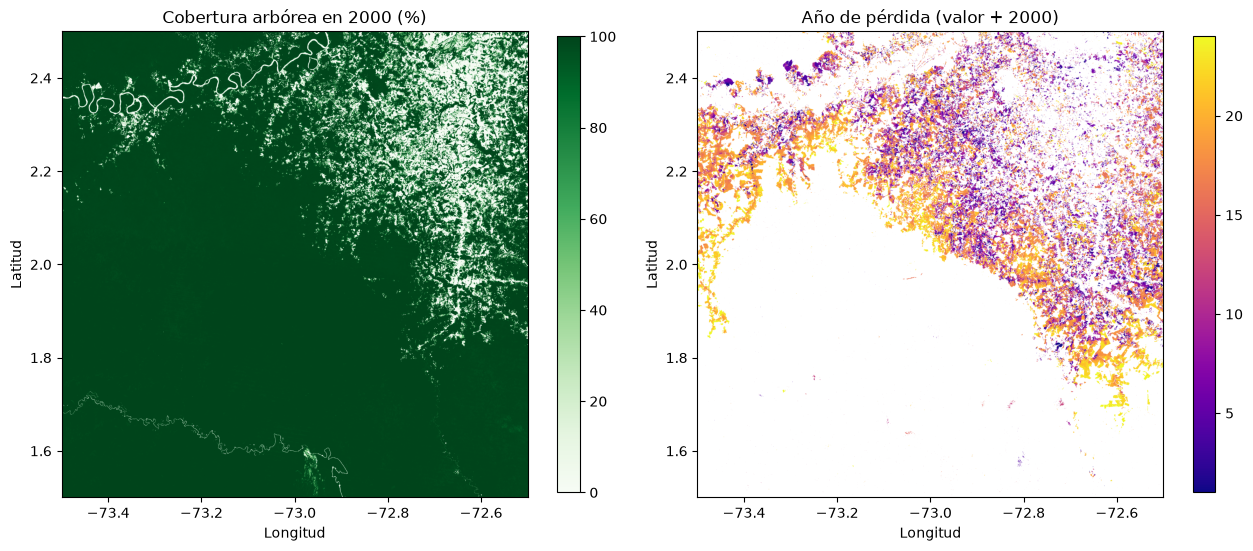

In [11]:
b = meta["bounds"]
extent = (b.left, b.right, b.bottom, b.top)

fig, ejes = plt.subplots(1, 2, figsize=(13, 6))

im0 = ejes[0].imshow(tc, extent=extent, cmap="Greens", vmin=0, vmax=100)
ejes[0].set_title("Cobertura arbórea en 2000 (%)")
plt.colorbar(im0, ax=ejes[0], shrink=0.8)

perdida_visible = np.ma.masked_equal(ly, 0)   # esconde los píxeles sin pérdida
im1 = ejes[1].imshow(perdida_visible, extent=extent, cmap="plasma", vmin=1, vmax=24)
ejes[1].set_title("Año de pérdida (valor + 2000)")
plt.colorbar(im1, ax=ejes[1], shrink=0.8)

for e in ejes:
    e.set_xlabel("Longitud")
    e.set_ylabel("Latitud")
plt.tight_layout()
plt.show()

## 5. Definir qué es "bosque"

`treecover2000` es un porcentaje, no un sí/no. Hay que elegir un umbral. Un valor muy usado es **30 %**.
También exigimos `datamask == 1` (tierra firme) para no contar agua ni píxeles sin datos.

El proyecto usa 30 % en todos los notebooks y en el agente; cambiar el umbral cambia todos los resultados siguientes.

In [12]:
BOSQUE_MIN = 30   # % mínimo de cobertura para llamar "bosque" a un píxel
bosque = (tc >= BOSQUE_MIN) & (dm == 1)

print(f"Bosque en el año 2000: {bosque.sum() * HA_POR_PIXEL:,.0f} ha "
      f"({bosque.mean() * 100:.1f}% de la zona)")

Bosque en el año 2000: 1,135,314 ha (91.7% de la zona)


## 6. ¿Cuánto bosque se perdió cada año?

`np.bincount` cuenta cuántas veces aparece cada valor. Si lo aplicamos a `lossyear` **solo en los píxeles de bosque**, obtenemos los píxeles perdidos por año. Multiplicando por las hectáreas de un píxel, tenemos hectáreas.

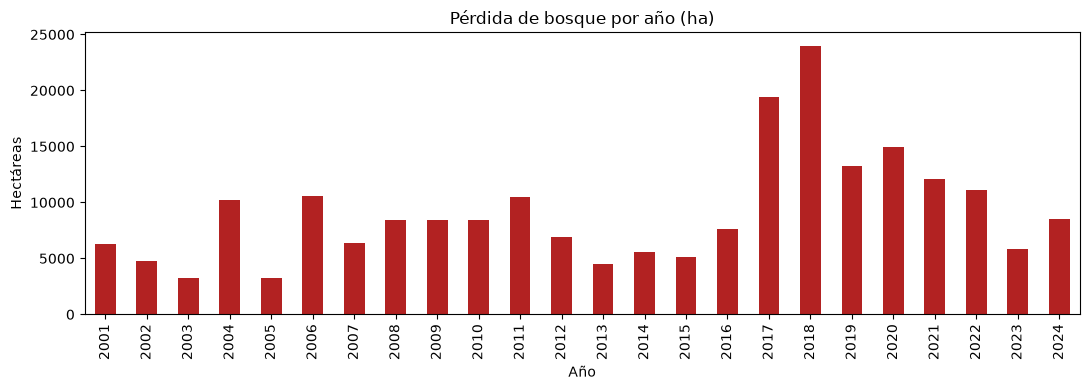

Años con más pérdida:
2018    23991.0
2017    19396.0
2020    14975.0
Name: perdida_ha, dtype: float64


In [13]:
conteo = np.bincount(ly[bosque], minlength=25)   # conteo[a] = píxeles perdidos en el año 2000 + a
perdida_ha = pd.Series(conteo[1:25] * HA_POR_PIXEL, index=range(2001, 2025), name="perdida_ha")

perdida_ha.plot(kind="bar", figsize=(11, 4), color="firebrick")
plt.title("Pérdida de bosque por año (ha)")
plt.xlabel("Año")
plt.ylabel("Hectáreas")
plt.tight_layout()
plt.show()

print("Años con más pérdida:")
print(perdida_ha.sort_values(ascending=False).head(3).round(0))

## 7. Comparar periodos (lo que hará el agente)

El agente compara "antes" contra "ahora". Aquí lo hacemos a mano: promedio anual histórico frente al promedio anual reciente, y un mapa que muestra dónde ocurrió cada cosa.

In [14]:
CORTE = 2022   # el periodo reciente empieza el año siguiente

historico = perdida_ha.loc[2001:CORTE]
reciente = perdida_ha.loc[CORTE + 1:2024]

print(f"Promedio anual 2001-{CORTE}: {historico.mean():,.0f} ha/año")
print(f"Promedio anual {CORTE + 1}-2024: {reciente.mean():,.0f} ha/año")
print(f"Razón reciente / histórico: {reciente.mean() / historico.mean():.2f}")

Promedio anual 2001-2022: 9,322 ha/año
Promedio anual 2023-2024: 7,179 ha/año
Razón reciente / histórico: 0.77


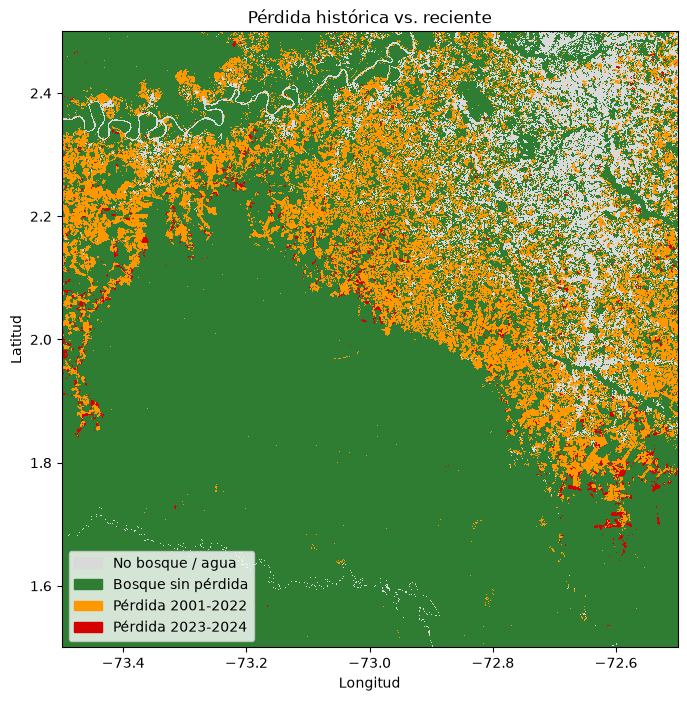

In [15]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

cat = np.zeros(ly.shape, dtype=np.uint8)                 # 0 = no es bosque
cat[bosque] = 1                                          # 1 = bosque sin pérdida
cat[bosque & (ly >= 1) & (ly <= CORTE - 2000)] = 2       # 2 = pérdida histórica
cat[bosque & (ly > CORTE - 2000)] = 3                    # 3 = pérdida reciente

colores = ["#d9d9d9", "#2e7d32", "#ff9800", "#d50000"]
etiquetas = ["No bosque / agua", "Bosque sin pérdida", f"Pérdida 2001-{CORTE}", f"Pérdida {CORTE + 1}-2024"]

plt.figure(figsize=(8, 8))
plt.imshow(cat, extent=extent, cmap=ListedColormap(colores), vmin=0, vmax=3, interpolation="nearest")
plt.legend(handles=[Patch(color=c, label=l) for c, l in zip(colores, etiquetas)], loc="lower left")
plt.title("Pérdida histórica vs. reciente")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

## 8. Guardar un resumen

Se guarda la tabla de pérdida por año en `outputs/perdida_por_anio_guaviare.csv`.

In [16]:
(RAIZ / "outputs").mkdir(exist_ok=True)
perdida_ha.rename_axis("anio").to_csv(RAIZ / "outputs" / f"perdida_por_anio_{ZONA}.csv")
print("Guardado en outputs/")

Guardado en outputs/


## Hallazgos

- **Año con más pérdida:** 2018, con 23,991 ha, unas 2.6 veces el promedio anual de 2001–2024 (≈ 9,140 ha/año).
- **Reciente frente a histórico:** 2023–2024 promedian 7,179 ha/año frente a 9,322 ha/año en 2001–2022 (razón 0.77): se pierde menos, pero la pérdida no se detiene.
- **Distribución:** la pérdida está concentrada en el norte y el oriente de la zona. La pérdida de 2023–2024 aparece en el borde de las áreas ya deforestadas, sobre el bloque de bosque continuo del sur, como un frente que avanza.
- **Limitación de la capa:** `lossyear` indica que hubo pérdida de cobertura y en qué año, pero no su causa: no distingue incendios, tala legal, plantaciones ni deforestación ilegal.